In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import myhousing as mh

q1

In [2]:
print(mh.price_category(39))
print(mh.price_category(75))
print(mh.price_category(120))

Budget
Mid-range
Premium


q2

In [3]:
df = pd.read_csv("../assignment-4/Bengaluru_House_Data.csv")

print("Shape:", df.shape)

Shape: (13320, 9)


In [4]:
print("\nFirst 10 rows:")
print(df.head(10))



First 10 rows:
              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   
5  Super built-up  Area  Ready To Move                Whitefield      2 BHK   
6  Super built-up  Area         18-May          Old Airport Road      4 BHK   
7  Super built-up  Area  Ready To Move              Rajaji Nagar      4 BHK   
8  Super built-up  Area  Ready To Move              Marathahalli      3 BHK   
9            Plot  Area  Ready To Move              Gandhi Bazar  6 Bedroom   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       260

In [5]:
print("\nColumn names:")
print(df.columns)



Column names:
Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='str')


In [6]:

print("\nUnique locations:")
print(df["location"].unique())



Unique locations:
<StringArray>
[                       'Electronic City Phase II',
                                'Chikka Tirupathi',
                                     'Uttarahalli',
                              'Lingadheeranahalli',
                                        'Kothanur',
                                      'Whitefield',
                                'Old Airport Road',
                                    'Rajaji Nagar',
                                    'Marathahalli',
                                    'Gandhi Bazar',
 ...
                               'Masjid e Alkareem',
                                   'Sindhi Colony',
                             'Kanakapur main road',
                       'Prasanna layout Herohalli',
                               'Sarvobhogam Nagar',
                                  'Pattegarhpalya',
                                     'Tilak Nagar',
 '12th cross srinivas nagar banshankari 3rd stage',
                          

In [7]:
new_df = df[["location", "size", "price"]]


In [8]:
print("\nSelected DataFrame:")
print(new_df.head())


Selected DataFrame:
                   location       size   price
0  Electronic City Phase II      2 BHK   39.07
1          Chikka Tirupathi  4 Bedroom  120.00
2               Uttarahalli      3 BHK   62.00
3        Lingadheeranahalli      3 BHK   95.00
4                  Kothanur      2 BHK   51.00


q3

In [9]:
# Filter houses with price below 50
filtered_df = df[df["price"] < 50]

In [10]:
print("Houses with price below 50:")
print(filtered_df)

Houses with price below 50:
                  area_type   availability                  location  \
0      Super built-up  Area         19-Dec  Electronic City Phase II   
5      Super built-up  Area  Ready To Move                Whitefield   
12     Super built-up  Area  Ready To Move        7th Phase JP Nagar   
13           Built-up  Area  Ready To Move                 Gottigere   
16     Super built-up  Area  Ready To Move             Bisuvanahalli   
...                     ...            ...                       ...   
13291            Plot  Area         18-Jan            Weavers Colony   
13302  Super built-up  Area  Ready To Move      Annaiah Reddy Layout   
13304  Super built-up  Area  Ready To Move     Raja Rajeshwari Nagar   
13312  Super built-up  Area  Ready To Move                 Bellandur   
13319  Super built-up  Area  Ready To Move              Doddathoguru   

            size  society total_sqft  bath  balcony  price  
0          2 BHK  Coomee        1056   2.0    

In [11]:
# Group by area_type and calculate mean price
mean_price = df.groupby("area_type")["price"].mean()
print("\nMean price by area type:")
print(mean_price)


Mean price by area type:
area_type
Built-up  Area          104.285498
Carpet  Area             89.502356
Plot  Area              208.495486
Super built-up  Area     92.971757
Name: price, dtype: float64


In [12]:
median_price = df.groupby("area_type")["price"].median()
print("\nMedian price by area type:")
print(median_price)



Median price by area type:
area_type
Built-up  Area           70.0
Carpet  Area             70.0
Plot  Area              140.0
Super built-up  Area     65.0
Name: price, dtype: float64


In [13]:
# five highest-priced listings
top_five = df.nlargest(5, "price")

print("\nFive highest-priced listings:")
print(top_five)


Five highest-priced listings:
                  area_type   availability         location        size  \
13067            Plot  Area  Ready To Move   Defence Colony  10 Bedroom   
11080  Super built-up  Area         18-Jan      Ashok Nagar       4 BHK   
13200            Plot  Area  Ready To Move   Defence Colony   6 Bedroom   
11763            Plot  Area  Ready To Move  Sadashiva Nagar   5 Bedroom   
3180   Super built-up  Area  Ready To Move  Shanthala Nagar       5 BHK   

       society total_sqft  bath  balcony   price  
13067      NaN       7150  13.0      NaN  3600.0  
11080      NaN       8321   5.0      2.0  2912.0  
13200      NaN       8000   6.0      3.0  2800.0  
11763      NaN       9600   7.0      2.0  2736.0  
3180   Kierser       8321   5.0      3.0  2700.0  


q4

In [14]:
# Count missing values in each column
print("Missing values:")
print(df.isnull().sum())

Missing values:
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64


In [15]:
clean_df = df.copy()

In [16]:
# Convert total_sqft into numeric values
clean_df["total_sqft"] = pd.to_numeric(
    clean_df["total_sqft"],
    errors="coerce"
)

In [17]:
# Remove rows with missing total_sqft or price
clean_df = clean_df.dropna(
    subset=["total_sqft", "price"]
)

In [18]:
print("\nRemaining rows after cleaning:")
print(len(clean_df))


Remaining rows after cleaning:
13073


q5

In [19]:

price_array = df["price"].to_numpy(dtype=float)


In [20]:
print("Mean:", np.nanmean(price_array))


Mean: 112.5656265015015


In [21]:

print("Median:", np.nanmedian(price_array))


Median: 72.0


In [22]:

print("Minimum:", np.nanmin(price_array))


Minimum: 8.0


In [23]:

print("Maximum:", np.nanmax(price_array))


Maximum: 3600.0


In [24]:
median = np.nanmedian(price_array)

mask = price_array > median

count = np.count_nonzero(mask)

print("Listings above median:", count)

Listings above median: 6589


# q6

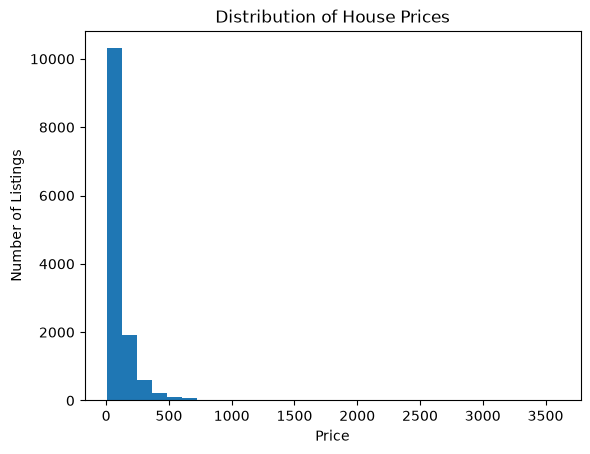

In [25]:
plt.hist(df["price"].dropna(), bins=30)

plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Number of Listings")

plt.show()

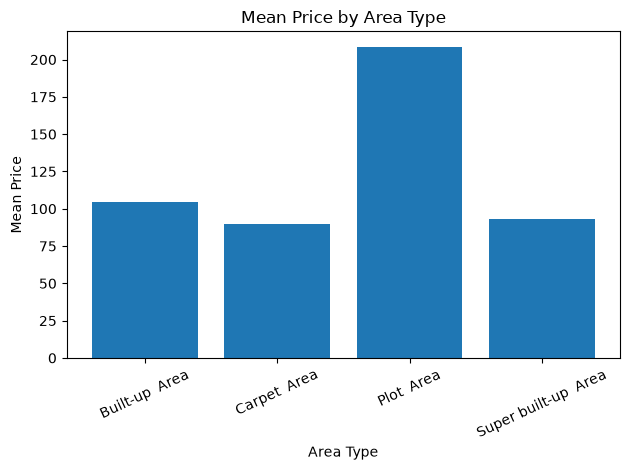

In [26]:
mean_price = df.groupby("area_type")["price"].mean()

plt.bar(mean_price.index, mean_price.values)

plt.title("Mean Price by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Mean Price")

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

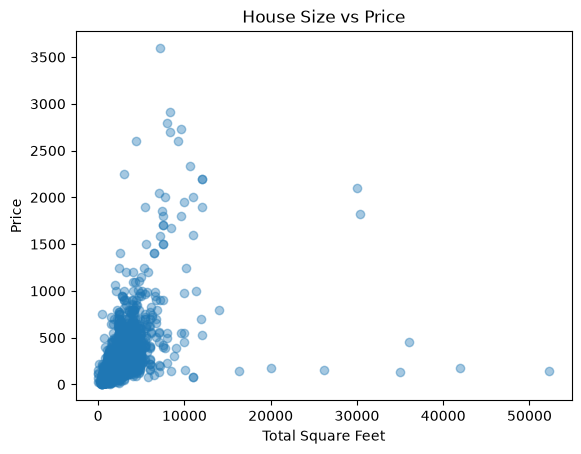

In [27]:
# Convert total_sqft into numeric values
plot_df = df[["total_sqft", "price"]].copy()

plot_df["total_sqft"] = pd.to_numeric(
    plot_df["total_sqft"],
    errors="coerce"
)

# Remove missing values
plot_df = plot_df.dropna()

plt.scatter(
    plot_df["total_sqft"],
    plot_df["price"],
    alpha=0.4
)

plt.title("House Size vs Price")
plt.xlabel("Total Square Feet")
plt.ylabel("Price")

plt.show()

q7

Mean price by area type:
area_type
Built-up  Area          104.285498
Carpet  Area             89.502356
Plot  Area              208.495486
Super built-up  Area     92.971757
Name: price, dtype: float64


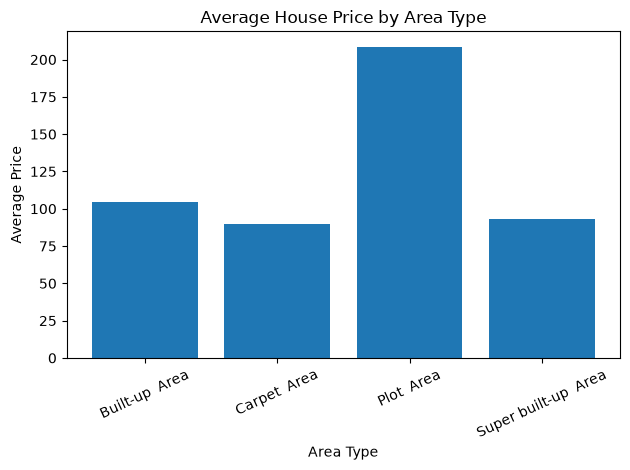

Chart saved successfully as housing_prices.png


In [28]:
df = pd.read_csv("../assignment-4/Bengaluru_House_Data.csv")

mean_price = df.groupby("area_type")["price"].apply(
    lambda x: np.nanmean(x.to_numpy(dtype=float))
)

print("Mean price by area type:")
print(mean_price)

plt.bar(mean_price.index, mean_price.values)

plt.title("Average House Price by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Average Price")

plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig("housing_prices.png", dpi=300)

plt.show()

print("Chart saved successfully as housing_prices.png")